Helper function

In [1]:
import numpy as np

def get_firing_matrix(firing_rates_dict):
    """
    Extracts and transposes the firing rate matrix from a dictionary.
    Returns a matrix of shape (T_bins, N_units).
    """
    all_units = list(firing_rates_dict.keys())
    firing_matrix = np.array([firing_rates_dict[unit]['firing_rate'] for unit in all_units])
    return firing_matrix.T  # (T_bins, N_units)
def compute_firing_rates(st_time, starttime, endtime, bin_size=1.0):
    """
    Computes firing rates for multiple units using vectorized operations.

    Parameters:
        st_time (list of np.ndarray): A list where each entry is an array of spike times for a unit.
        starttime (float): The start time of the epoch.
        endtime (float): The end time of the epoch.
        bin_size (float, optional): The size of the bins in seconds. Default is 1.0.

    Returns:
        dict: A dictionary where each key is 'unitX' and values contain firing rates and time bin centers.
    """
    # Generate time bins
    bins = np.arange(starttime, endtime + bin_size, bin_size)
    time_bin_centers = bins[:-1] + (bin_size / 2)  # Compute the center of each time bin

    # Convert spike times list to a NumPy array (object dtype for jagged arrays)
    spike_times_array = np.array(st_time, dtype=object)

    # Compute spike counts using vectorized histogram
    spike_counts = np.array([
        np.histogram(spike_times[(spike_times >= starttime) & (spike_times < endtime)], bins=bins)[0]
        for spike_times in spike_times_array
    ])

    # Calculate firing rates (spike count per second)
    firing_rates = spike_counts / bin_size  # Shape: (num_units, num_bins)

    # Store results in a dictionary
    firing_rates_dict = {
        f'unit{idx + 1}': {'firing_rate': firing_rates[idx], 'time_stamps': time_bin_centers}
        for idx in range(len(spike_times_array))
    }

    return firing_rates_dict
import numpy as np

def filter_nrem_hse_fast(firing_rates_dict, NREM_HSE_epochs):
    """
    Filters firing rates to keep only bins within NREM_HSE epochs (optimized for speed).

    Parameters:
        firing_rates_dict (dict): Output from `compute_firing_rates`, containing firing rates and time stamps.
        NREM_HSE_epochs (np.ndarray): An array of shape (num_epochs, 2) where each row is [start, stop] time.

    Returns:
        dict: Filtered version of `firing_rates_dict`, keeping only time bins within NREM_HSE epochs.
    """
    filtered_firing_rates = {}

    # Sort NREM_HSE_epochs for faster searching
    sorted_epochs = np.sort(NREM_HSE_epochs, axis=0)

    for unit, data in firing_rates_dict.items():
        firing_rate = data['firing_rate']
        time_stamps = data['time_stamps']

        # Fast lookup: Find which epochs each time bin belongs to
        idx_starts = np.searchsorted(sorted_epochs[:, 0], time_stamps, side="right") - 1
        idx_ends = np.searchsorted(sorted_epochs[:, 1], time_stamps, side="left")

        # A valid time bin is inside an epoch if the start index == end index
        mask = (idx_starts == idx_ends) & (idx_starts >= 0) & (idx_starts < len(sorted_epochs))

        # Apply mask to filter time bins
        filtered_firing_rates[unit] = {
            'firing_rate': firing_rate[mask],
            'time_stamps': time_stamps[mask]
        }

    return filtered_firing_rates
def compute_ripple_rate(ripple_timestamps, bin_centers, bin_size=1.0):
    """
    Computes ripple rate (ripples per second) in each bin.

    Parameters:
        ripple_timestamps (np.ndarray): 1D array of ripple event times (e.g., ripple peaks).
        bin_centers (np.ndarray): 1D array of time points corresponding to the center of each bin.
        bin_size (float): Bin size in seconds.

    Returns:
        np.ndarray: Ripple rate (Hz) per bin.
    """
    half_bin = bin_size / 2.0
    # Construct bin edges from centers
    bin_edges = np.concatenate(([bin_centers[0] - half_bin], bin_centers + half_bin))

    ripple_counts, _ = np.histogram(ripple_timestamps, bins=bin_edges)
    return ripple_counts / bin_size  # ripple rate in Hz
import numpy as np
import pandas as pd

import numpy as np
import pandas as pd
def compute_population_synchrony_from_hist(E_spikes, bin_size=0.025):
    """
    Compute population synchrony from spike trains by:
    1. Binning into 25ms bins using np.histogram
    2. Aggregating every 2 bins (50ms) to compute synchrony

    Parameters:
        E_spikes (list of np.arrays): spike times for each unit
        bin_size (float): bin size in seconds (default 25ms)

    Returns:
        pd.DataFrame: columns ['time', 'synchrony']
    """
    num_units = len(E_spikes)

    # Get global time range
    all_spikes = np.concatenate(E_spikes)
    t_min = np.min(all_spikes)
    t_max = np.max(all_spikes)

    # Bin edges for 25ms
    bin_edges = np.arange(t_min, t_max + bin_size, bin_size)
    n_bins = len(bin_edges) - 1

    # Fill firing rate matrix
    firing_matrix = np.zeros((num_units, n_bins), dtype=int)
    for unit_idx, spikes in enumerate(E_spikes):
        counts, _ = np.histogram(spikes, bins=bin_edges)
        firing_matrix[unit_idx] = counts

    # Compute synchrony across every 50ms (2-bin) chunk
    step = 2
    sync = []
    time_centers = []

    for i in range(0, n_bins - 1, step):
        activity = np.sum(firing_matrix[:, i:i+2], axis=1)
        frac_active = np.sum(activity > 0) / num_units
        sync.append(frac_active)
        time_centers.append((bin_edges[i] + bin_edges[i+2]) / 2)

    return pd.DataFrame({
        'time': time_centers,
        'synchrony': sync
    })



Loading everything

In [2]:


import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from skimage import measure
import os

import logging

logging.getLogger().setLevel(logging.ERROR)
basepath = r"W:\data\PPP\PPP21\day4"
basename=os.path.basename(basepath)# Define the new folder path
#create working folder
new_folder_path = os.path.join(basepath, "complex_system")
brain_region="CA1"
animal="mouse"   #or Mouse
cell_type='all'
path_parts = basepath.split("\\")  # Split the path using backslash
animal_name = path_parts[-2]  # Second-to-last part is the animal name
day = path_parts[-1]  # Last part is the day
save_dir = r"D:\Documents\GitHub\R_Project\PPP\codebook\Criticality_analysis\avalanche"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
# Create the folder if it doesn't exist
if not os.path.exists(new_folder_path):
    os.makedirs(new_folder_path)
    print(f"Folder created: {new_folder_path}")
else:
    print(f"Folder already exists: {new_folder_path}")
# load in spike data from hpc pyramidal cells
st, cm = loading.load_spikes(
    basepath, brainRegion=brain_region ,                    # putativeCellType="Pyr"
)
# load theta epochs
state_dict = loading.load_SleepState_states(basepath)
nrem_epochs = nel.EpochArray(
    state_dict["NREMstate"],
)
awake_epochs = nel.EpochArray(
    state_dict["WAKEstate"],
)
rem_epochs = nel.EpochArray(
    state_dict["REMstate"],
)
import scipy.io
""" file_path = os.path.join(basepath, f"HSE_epochs.mat")
mat_data = scipy.io.loadmat(file_path)
HSE_epochs = mat_data['HSE_epochs'] """
epoch_df = loading.load_epoch(basepath)
sleep_epochs = nel.EpochArray(np.array([epoch_df.startTime, epoch_df.stopTime]).T)
spike_times = st.time # From your code
E_spikes = st.time[(cm.putativeCellType == 'Pyramidal Cell')]
E_CellID=cm.UID[(cm.putativeCellType == 'Pyramidal Cell')]
E_firingrate=cm.firingRate[(cm.putativeCellType == 'Pyramidal Cell')]
I_spikes= st.time[(cm.putativeCellType.str.contains("Interneuron"))]
I_CellID=cm.UID[(cm.putativeCellType.str.contains("Interneuron"))]

Folder already exists: W:\data\PPP\PPP21\day4\complex_system


KeyboardInterrupt: 

In [3]:
import numpy as np
import scipy.io as sio  
# Load ripple events
ripple_events = loading.load_ripples_events(basepath=basepath)
ripple_epochs = nel.EpochArray(np.array([ripple_events.peaks, ripple_events.peaks]).T)
    # Load barrage events

try:
    # Load barrage events
    #brpath=r"W:\data\PPP\CA2\PPP7\day8"
    barrage_events = loading.load_barrage_events(basepath=basepath)  
    # Create barrage epochs
    barrage_epochs = nel.EpochArray(np.array([barrage_events.start, barrage_events.stop]).T)
    # Find barrages in NREM epochs
    barrages_in_nrem = barrage_epochs & nrem_epochs
    mat_path = os.path.join(basepath, f'{basename}.HSEn2.events.mat')

    data = scipy.io.loadmat(mat_path, struct_as_record=False, squeeze_me=True)
    barrage = data['HSEn2']
    barrage_timestamps= barrage.timestamps 
    # Extract start times
except Exception as e:
    # General exception for unexpected errors
    print(f"No barrage file: {e}")
    barrage_epochs=[]
try:
    # Load barrage events
    # Create barrage epochs
    mat_path = os.path.join(basepath, f'{basename}.deltaWaves.events.mat')

    data = scipy.io.loadmat(mat_path, struct_as_record=False, squeeze_me=True)
    deltaWaves = data['deltaWaves']
    delta_events= deltaWaves.timestamps 
    # Extract start times
except Exception as e:
    # General exception for unexpected errors
    print(f"No barrage file: {e}")
    delta_events=[]
try:# Step 2: Get the common time bins (already defined)
    matfile = os.path.join(basepath, "all_d2.mat")
    matdata = sio.loadmat(matfile)
    # Step 2: Get the common time bins (already defined)
    # Assuming the variable is named 'all_d2' inside the file:
    all_d2 = matdata["all_d2"]
except Exception as e:
    # General exception for unexpected errors
    print(f"No d2 file: {e}")
    all_d2 = []
# Extract pre-sleep epoch
# Example: pre-sleep indices
pre_sleep_idx = [0]
# Collect all intervals from those indices
pre_intervals = np.array([
    [epoch_df.startTime[i], epoch_df.stopTime[i]]
    for i in pre_sleep_idx
])
# Build EpochArray with multiple rows
pre_epoch = nel.EpochArray(pre_intervals)
# Overlap with state epochs
pre_NREM  = pre_epoch & nrem_epochs[nrem_epochs.durations > 0]
pre_awake = pre_epoch & awake_epochs[awake_epochs.durations > 0]
pre_REM   = pre_epoch & rem_epochs[rem_epochs.durations > 0]
# Extract middle sleep epoch
mid_sleep_idx = [2]
mid_intervals = np.array([[epoch_df.startTime[i], epoch_df.stopTime[i]] for i in mid_sleep_idx])
mid_epoch = nel.EpochArray(mid_intervals)
mid_NREM = mid_epoch & nrem_epochs[nrem_epochs.durations > 0]  # Filter by NREM duration
mid_awake=mid_epoch & awake_epochs[awake_epochs.durations > 0] 
mid_REM=mid_epoch & rem_epochs[rem_epochs.durations > 0] 
# Extract post-sleep epoch
post_sleep_idx = [4]
post_intervals = np.array([[epoch_df.startTime[i], epoch_df.stopTime[i]] for i in post_sleep_idx])
post_epoch = nel.EpochArray(post_intervals)
post_NREM = post_epoch & nrem_epochs[nrem_epochs.durations >0]  # Compute overlapping epochs
post_awake=post_epoch & awake_epochs[awake_epochs.durations > 0] 
post_REM=post_epoch & rem_epochs[rem_epochs.durations > 0] 
def adjust_intervals(intervals, target):
    """
    Adjust intervals to sum to exactly the target duration.
    
    If the accumulated duration plus the next interval exceeds the target,
    a partially trimmed interval is added.
    """
    adjusted = []
    accumulated = 0
    for start, end in intervals:
        duration = end - start
        if accumulated + duration < target:
            adjusted.append((start, end))
            accumulated += duration
        else:
            # Calculate remaining time needed
            remaining = target - accumulated
            if remaining > 0:
                # Append the trimmed interval
                adjusted.append((start, start + remaining))
            break
    return adjusted

# Compute the total durations
total_pre = sum(pre_NREM.durations)
total_mid = sum(mid_NREM.durations)
total_post = sum(post_NREM.durations)

# Set the target duration to the smallest total duration
target_duration = max(total_pre, total_mid, total_post)

# Get NREM intervals
pre_intervals = pre_NREM.data
mid_intervals = mid_NREM.data
post_intervals = post_NREM.data

# Adjust all sets of intervals
adjusted_pre_intervals = adjust_intervals(pre_intervals, target_duration)
adjusted_mid_intervals = adjust_intervals(mid_intervals, target_duration)
adjusted_post_intervals = adjust_intervals(post_intervals, target_duration)

# Convert adjusted intervals into EpochArrays
pre_NREMs = nel.EpochArray(np.array(adjusted_pre_intervals))
mid_NREMs = nel.EpochArray(np.array(adjusted_mid_intervals))
post_NREMs = nel.EpochArray(np.array(adjusted_post_intervals))

# Find ripples occurring within each adjusted epoch
ripples_in_pre = ripple_epochs & pre_NREMs
ripples_in_mid = ripple_epochs & mid_NREMs
ripples_in_post = ripple_epochs & post_NREMs
if isinstance(barrage_epochs, nel.EpochArray):
    barrages_in_pre = barrage_epochs & pre_NREMs
    barrages_in_mid = barrage_epochs & mid_NREMs
    barrages_in_post = barrage_epochs & post_NREMs
else:
    barrages_in_pre = barrages_in_mid = barrages_in_post = None
# Print final durations for verification
print(f"Adjusted Pre-Sleep NREM Duration: {sum(pre_NREMs.durations)} sec")
print(f"Adjusted Mid-Sleep NREM Duration: {sum(mid_NREMs.durations)} sec")
print(f"Adjusted Post-Sleep NREM Duration: {sum(post_NREMs.durations)} sec")
# matfile = os.path.join(basepath, 'swslope.mat')
# data = scipy.io.loadmat(matfile)
# swslope_array = data['swslope']
##sia_data = scipy.io.loadmat(sia_event_path)
#SIA_periods = sia_data['SIA_periods']


No barrage file: 'DataFrame' object has no attribute 'start'
No barrage file: [Errno 2] No such file or directory: 'W:\\data\\PPP\\PPP21\\day4\\day4.deltaWaves.events.mat'
No d2 file: [Errno 2] No such file or directory: 'W:\\data\\PPP\\PPP21\\day4\\all_d2.mat'
Adjusted Pre-Sleep NREM Duration: 2515.0 sec
Adjusted Mid-Sleep NREM Duration: 3349.0 sec
Adjusted Post-Sleep NREM Duration: 39.0 sec


D:\Documents\GitHub\neuro_py\neuro_py\io\loading.py:1036: UserWarning: No barrage file found for W:\data\PPP\PPP21\day4


Bin ripples

In [4]:
import numpy as np
import pandas as pd
import umap
import plotly.express as px
from scipy.ndimage import gaussian_filter1d
from scipy.stats import zscore

# ----------------------------------------------------------
# Loop over different bin sizes (assuming bin_sizes is defined)
# ----------------------------------------------------------
bin_sizes = [1]
sigma = 1
starttime = 0
endtime = epoch_df.stopTime.iloc[-1]  # From your code

for current_bin_size in bin_sizes:
    print(f"\n=== Processing bin_size = {current_bin_size} ===")

    # 1) Compute firing rates for the current bin size
    firing_rates = compute_firing_rates(spike_times, starttime, endtime, current_bin_size)

    # 2) Smooth and z-score firing rates
    smoothed_zscored_rates = {}
    for unit, data in firing_rates.items():
        rates = data['firing_rate']
        smoothed_rates = gaussian_filter1d(rates, sigma=sigma)  # Smooth with Gaussian kernel
        zscored_rates = zscore(smoothed_rates)  # Z-score normalization

        smoothed_zscored_rates[unit] = {
            'firing_rate': zscored_rates,
            'time_stamps': data['time_stamps']
        }

    # 3) Filter into pre-, middle-, and post-sleep epochs
    pre_filtered_firing_rates = filter_nrem_hse_fast(smoothed_zscored_rates, adjusted_pre_intervals)
    mid_filtered_firing_rates = filter_nrem_hse_fast(smoothed_zscored_rates, adjusted_mid_intervals)
    post_filtered_firing_rates = filter_nrem_hse_fast(smoothed_zscored_rates, adjusted_post_intervals)

    # 4) Extract firing rate matrices
    pre_firing_matrix = get_firing_matrix(pre_filtered_firing_rates)
    mid_firing_matrix = get_firing_matrix(mid_filtered_firing_rates)
    post_firing_matrix = get_firing_matrix(post_filtered_firing_rates)

    # 5) Concatenate for classification/embedding
    X = np.concatenate((pre_firing_matrix, mid_firing_matrix, post_firing_matrix), axis=0)
    y = np.concatenate((
        np.zeros(pre_firing_matrix.shape[0]),  # Label 0 for pre
        np.ones(mid_firing_matrix.shape[0]),   # Label 1 for mid
        np.full(post_firing_matrix.shape[0], 2)  # Label 2 for post
    ))

    pre_timestamps = pre_filtered_firing_rates[list(pre_filtered_firing_rates.keys())[0]]['time_stamps']
    mid_timestamps = mid_filtered_firing_rates[list(mid_filtered_firing_rates.keys())[0]]['time_stamps']
    post_timestamps = post_filtered_firing_rates[list(post_filtered_firing_rates.keys())[0]]['time_stamps']

    # Compute ripple rates
    pre_ripple_rate = compute_ripple_rate(ripples_in_pre.data, pre_timestamps)
    mid_ripple_rate = compute_ripple_rate(ripples_in_mid.data, mid_timestamps)
    post_ripple_rate = compute_ripple_rate(ripples_in_post.data, post_timestamps)




c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html



=== Processing bin_size = 1 ===


high ripple and low ripple avalanche

In [5]:
import numpy as np

def get_ripple_intervals(bin_centers, ripple_rate, bin_size, threshold=0.1, min_consecutive_bins=1):
    """
    Finds consecutive intervals where the ripple rate is below a given threshold (low ripple intervals)
    and consecutive intervals where the ripple rate is at or above the threshold (high ripple intervals).

    Parameters:
        bin_centers (np.ndarray): 1D array of time points corresponding to the centers of bins.
        ripple_rate (np.ndarray): 1D array of ripple rates (Hz) corresponding to each bin.
        bin_size (float): Size of each time bin in seconds.
        threshold (float): Ripple rate threshold (Hz). Bins with ripple_rate < threshold are considered low.
        min_consecutive_bins (int): Minimum number of consecutive bins to form a valid interval.
        
    Returns:
        low_intervals (list of tuples): Each tuple is (start_time, end_time) of a low ripple interval.
        high_intervals (list of tuples): Each tuple is (start_time, end_time) of a high ripple interval.
    """
    low_intervals = []
    high_intervals = []
    
    current_low_start = None
    current_high_start = None

    for i, rate in enumerate(ripple_rate):
        if rate < threshold:
            # If we are in a high interval, close it.
            if current_high_start is not None:
                if (i - current_high_start) >= min_consecutive_bins:
                    start_time = bin_centers[current_high_start] - bin_size / 2.0
                    end_time = bin_centers[i - 1] + bin_size / 2.0
                    high_intervals.append((start_time, end_time))
                current_high_start = None
            # Start or continue a low interval.
            if current_low_start is None:
                current_low_start = i
        else:
            # If we are in a low interval, close it.
            if current_low_start is not None:
                if (i - current_low_start) >= min_consecutive_bins:
                    start_time = bin_centers[current_low_start] - bin_size / 2.0
                    end_time = bin_centers[i - 1] + bin_size / 2.0
                    low_intervals.append((start_time, end_time))
                current_low_start = None
            # Start or continue a high interval.
            if current_high_start is None:
                current_high_start = i

    # Handle any ongoing interval at the end of the array.
    if current_low_start is not None and (len(ripple_rate) - current_low_start) >= min_consecutive_bins:
        start_time = bin_centers[current_low_start] - bin_size / 2.0
        end_time = bin_centers[-1] + bin_size / 2.0
        low_intervals.append((start_time, end_time))
        
    if current_high_start is not None and (len(ripple_rate) - current_high_start) >= min_consecutive_bins:
        start_time = bin_centers[current_high_start] - bin_size / 2.0
        end_time = bin_centers[-1] + bin_size / 2.0
        high_intervals.append((start_time, end_time))
        
    return low_intervals, high_intervals




In [6]:
bin_size =1
min_consecutive_bins = 1# or adjust as needed
pre_low_intervals,pre_high_intervals = get_ripple_intervals(pre_timestamps, pre_ripple_rate, bin_size,
                                             threshold=0.1, min_consecutive_bins=min_consecutive_bins)
mid_low_intervals,mid_high_intervals  = get_ripple_intervals(mid_timestamps, mid_ripple_rate, bin_size,
                                             threshold=0.1, min_consecutive_bins=min_consecutive_bins)
post_low_intervals,post_high_intervals = get_ripple_intervals(post_timestamps, post_ripple_rate, bin_size,
                                              threshold=0.1, min_consecutive_bins=min_consecutive_bins)
all_low_intervals = pre_low_intervals + mid_low_intervals + post_low_intervals



In [7]:

# Compute total durations
def total_duration(intervals):
    """Compute total duration from a list of [start, end] intervals."""
    return sum(end - start for start, end in intervals)

# Low ripple durations
pre_low_duration = total_duration(pre_low_intervals)
mid_low_duration = total_duration(mid_low_intervals)
post_low_duration = total_duration(post_low_intervals)
all_low_intervals = pre_low_intervals + mid_low_intervals + post_low_intervals
all_low_duration = total_duration(all_low_intervals)

# High ripple durations
pre_high_duration = total_duration(pre_high_intervals)
mid_high_duration = total_duration(mid_high_intervals)
post_high_duration = total_duration(post_high_intervals)
all_high_intervals = pre_high_intervals + mid_high_intervals + post_high_intervals
all_high_duration = total_duration(all_high_intervals)

# Print results
print("=== Low Ripple Durations ===")
print(f"Pre:  {pre_low_duration:.2f} sec")
print(f"Mid:  {mid_low_duration:.2f} sec")
print(f"Post: {post_low_duration:.2f} sec")
print(f"Total Low Ripple:  {all_low_duration:.2f} sec")

print("\n=== High Ripple Durations ===")
print(f"Pre:  {pre_high_duration:.2f} sec")
print(f"Mid:  {mid_high_duration:.2f} sec")
print(f"Post: {post_high_duration:.2f} sec")
print(f"Total High Ripple: {all_high_duration:.2f} sec")
def match_interval_durations(low_intervals, high_intervals):
    """Trim the longer list of intervals so both have the same total duration."""
    def trim_intervals(intervals, target_duration):
        trimmed = []
        total = 0
        for start, end in intervals:
            duration = end - start
            if total + duration <= target_duration:
                trimmed.append((start, end))
                total += duration
            else:
                # Clip the final interval to fit exactly
                needed = target_duration - total
                if needed > 0:
                    trimmed.append((start, start + needed))
                    total += needed
                break
        return trimmed

    dur_low = total_duration(low_intervals)
    dur_high = total_duration(high_intervals)

    if dur_low > dur_high:
        low_intervals = trim_intervals(low_intervals, dur_high)
    elif dur_high > dur_low:
        high_intervals = trim_intervals(high_intervals, dur_low)

    return low_intervals, high_intervals
# For pre
pre_low_intervals, pre_high_intervals = match_interval_durations(pre_low_intervals, pre_high_intervals)

# For mid
mid_low_intervals, mid_high_intervals = match_interval_durations(mid_low_intervals, mid_high_intervals)

# For post
post_low_intervals, post_high_intervals = match_interval_durations(post_low_intervals, post_high_intervals)

# === Print durations ===
print("=== Adjusted Low Ripple Durations ===")
print(f"Pre:  {total_duration(pre_low_intervals):.2f} sec")
print(f"Mid:  {total_duration(mid_low_intervals):.2f} sec")
print(f"Post: {total_duration(post_low_intervals):.2f} sec")

print("\n=== Adjusted High Ripple Durations ===")
print(f"Pre:  {total_duration(pre_high_intervals):.2f} sec")
print(f"Mid:  {total_duration(mid_high_intervals):.2f} sec")
print(f"Post: {total_duration(post_high_intervals):.2f} sec")
all_low_intervals  = pre_low_intervals + mid_low_intervals + post_low_intervals
all_high_intervals = pre_high_intervals + mid_high_intervals + post_high_intervals
import os
import pandas as pd
import numpy as np
pre_duration= total_duration(pre_low_intervals)
mid_duration= total_duration(mid_low_intervals)
post_duration= total_duration(post_low_intervals)
# 1) Load
csv_path = r"D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\dcc_all_all_sleep.csv"
df = pd.read_csv(csv_path)

# If the CSV used 'animal' instead of 'animal_name'
if "animal_name" not in df.columns and "animal" in df.columns:
    df["animal_name"] = df["animal"].astype(str)

# 2) Parse animal/day from your folder path
day_dir = basepath  # <-- change as needed
parts = os.path.normpath(day_dir).split(os.sep)
animal_name = parts[-2]
day = parts[-1]

# 3) Map idx → label (optional) and normalize index column name
sleep_col = "sleep_idx" if "sleep_idx" in df.columns else "sleep_index"
df[sleep_col] = pd.to_numeric(df[sleep_col], errors="coerce")
idx2label = {0: "pre", 2: "mid", 4: "post"}
df["sleep_interval"] = df[sleep_col].map(idx2label)

# 4) Your three durations (in seconds or whatever unit you use)
pre_duration  = float(pre_duration)   # e.g., total_duration(pre_low_intervals)
mid_duration  = float(mid_duration)   # e.g., total_duration(mid_low_intervals)
post_duration = float(post_duration)  # e.g., total_duration(post_low_intervals)

idx2dur = {0: pre_duration, 2: mid_duration, 4: post_duration}

# 5) Assign only for the matching animal/day rows
mask = (df["animal_name"] == animal_name) & (df["day"] == day)
df.loc[mask, "total_duration"] = df.loc[mask, sleep_col].map(idx2dur).astype(float)

# (Optional) Save back
df.to_csv(csv_path, index=False)


=== Low Ripple Durations ===
Pre:  4391.00 sec
Mid:  3964.00 sec
Post: 18.00 sec
Total Low Ripple:  8373.00 sec

=== High Ripple Durations ===
Pre:  1116.00 sec
Mid:  2269.00 sec
Post: 72.00 sec
Total High Ripple: 3457.00 sec
=== Adjusted Low Ripple Durations ===
Pre:  1116.00 sec
Mid:  2269.00 sec
Post: 18.00 sec

=== Adjusted High Ripple Durations ===
Pre:  1116.00 sec
Mid:  2269.00 sec
Post: 18.00 sec


In [ ]:
import os
import pandas as pd
from criticality.av_analysis import (
        coarse_grain_avalanche_detection_all_units_intervals,
        plot_power_law_ccdf,
        plot_dcc,
        compute_scaling_with_avg
    )
def run_dcc_pipeline(
    st_time,
    bin_size,
    pre_low_intervals,
    pre_high_intervals,
    xmins_size,
    xmaxs_size,
    xmins_dur,
    xmaxs_dur,
    animal_name,
    day,
    sleep_idx,
    animal,
    brain_region,
    cell_type,
    base_dir,
    csv_path_dcc=r'D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\dcc_all_all_sleep.csv',
    csv_path_beta=r'D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\av_beta_all_sleep.csv',
    plot_scaling=True
):
    from criticality.av_analysis import (
        coarse_grain_avalanche_detection_all_units_intervals,
        plot_power_law_ccdf,
        plot_dcc,
        compute_scaling_with_avg
    )

    # Avalanche detection
    aval_sizes_low, aval_durs_low, *_ = coarse_grain_avalanche_detection_all_units_intervals(
        st_time, bin_size, pre_low_intervals)
    aval_sizes_high, aval_durs_high, *_ = coarse_grain_avalanche_detection_all_units_intervals(
        st_time, bin_size, pre_high_intervals)
 
    # Prepare data dictionaries
    data_dict_sizes = {'low_ripple': aval_sizes_low, 'high_ripple': aval_sizes_high}
    data_dict_durations = {'low_ripple': aval_durs_low, 'high_ripple': aval_durs_high}
    data_dict = {'low_ripple': (aval_sizes_low, aval_durs_low), 'high_ripple': (aval_sizes_high, aval_durs_high)}

    # Plot power-law CCDF for size
    title_sizes = f"{animal_name}_{day}_{brain_region}_{cell_type}_{sleep_idx}_Avalanche Size CCDF"
    plot_file_name = f"av_size_{animal_name}_{day}_{brain_region}_{cell_type}_{sleep_idx}_lh_ripples.png"
    save_path_size = os.path.join(base_dir, plot_file_name)
    alpha_size_dict = plot_power_law_ccdf(data_dict_sizes, xmins_size, xmaxs_size,
                                          "Avalanche Size", "CCDF", title_sizes,
                                          animal_name, day, animal, sleep_idx,
                                          save_path=save_path_size, csv_path=r'D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\av_size_all_sleep.csv', brain_region=brain_region)

    # Plot power-law CCDF for durations
    title_durations = f"{animal_name}_{day}_{brain_region}_{cell_type}_{sleep_idx}_Avalanche Duration CCDF"
    plot_file_name = f"av_durations_{animal_name}_{day}_{brain_region}_{cell_type}_{sleep_idx}_lh_ripples.png"
    save_path_dur = os.path.join(base_dir, plot_file_name)
    alpha_duration_dict = plot_power_law_ccdf(data_dict_durations, xmins_dur, xmaxs_dur,
                                              "Avalanche Duration", "CCDF", title_durations,
                                              animal_name, day, animal, sleep_idx,
                                              save_path=save_path_dur, csv_path=r'D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\av_duration_all_sleep.csv', brain_region=brain_region)

    # Compute scaling slope β from mean size vs duration
    title_scaling = "Avalanche Size-Duration Relationship"
    plot_file_name = f"av_scaling_law_{animal_name}_{day}_{brain_region}_{sleep_idx}_lh_ripples.png"
    save_path_scaling = os.path.join(base_dir, plot_file_name) if plot_scaling else None
    obs_beta_dict = compute_scaling_with_avg(data_dict, "Duration", "Size", title_scaling,
                                             animal_name, day, sleep_idx, animal,
                                             save_path=save_path_scaling,
                                             csv_path=csv_path_beta,
                                             brain_region=brain_region)

    # Compute DCC
    dcc_dict = {}
    for label in alpha_size_dict.keys():
        alpha_size = alpha_size_dict[label]
        alpha_dur = alpha_duration_dict[label]
        obs_beta = obs_beta_dict[label]
        beta_predicted = (alpha_dur - 1) / (alpha_size - 1)  # crackling noise scaling
        dcc = abs(obs_beta - beta_predicted)
        dcc_dict[label] = {
            "beta_predicted": beta_predicted,
            "obs_beta": obs_beta,
            "dcc": dcc
        }

    # Save to CSV
    results = []
    for label, values in dcc_dict.items():
        results.append({
            "animal_name": animal_name,
            "day": day,
            "sleep_idx": sleep_idx,
            "cell_type":cell_type,
            "label": label,
            "beta_predicted": values["beta_predicted"],
            "obs_beta": values["obs_beta"],
            "dcc": values["dcc"],
            "Region": brain_region,
            "animal": animal
        })

    results_df = pd.DataFrame(results)
    if csv_path_dcc:
        if os.path.exists(csv_path_dcc):
            existing_df = pd.read_csv(csv_path_dcc)
            existing_df = existing_df[~(
                (existing_df["animal_name"] == animal_name) &
                (existing_df["day"] == day) &
                (existing_df["sleep_idx"] == sleep_idx) &
                (existing_df["label"].isin(results_df["label"])) &
                (existing_df["Region"].isin(results_df["Region"]))
            )]
            updated_df = pd.concat([existing_df, results_df], ignore_index=True)
        else:
            updated_df = results_df
        updated_df.to_csv(csv_path_dcc, index=False)
        print(f"Results saved to {csv_path_dcc}")

    return dcc_dict


Calculating best minimal value for power law fit
low_ripple - KS Statistic: 0.0313, Alpha: 2.01, Xmin: 143.0,Xmax: 0
Lognormal vs Power-law: R=-0.0002307640339953565, p=0.9950072218523991
Exponential vs Power-law: R=383.13538008633685, p=1.7500561156746308e-16
Calculating best minimal value for power law fit
high_ripple - KS Statistic: 0.0604, Alpha: 3.50, Xmin: 559.0,Xmax: 0
Lognormal vs Power-law: R=-7.569205927669387, p=0.02122713074458475
Exponential vs Power-law: R=-6.266475041131663, p=0.24770964841537813


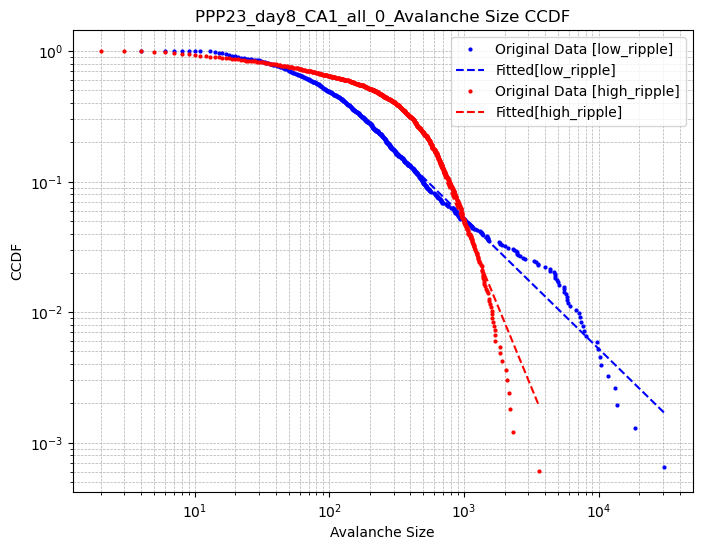

Results saved to D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\av_size_all_sleep.csv
Calculating best minimal value for power law fit
low_ripple - KS Statistic: 0.0234, Alpha: 2.10, Xmin: 5.0,Xmax: 0
Lognormal vs Power-law: R=-0.3368504136485311, p=0.5433904489407246
Exponential vs Power-law: R=263.03582516328834, p=3.138966719495204e-11
Calculating best minimal value for power law fit
high_ripple - KS Statistic: 0.0324, Alpha: 3.59, Xmin: 14.0,Xmax: 0
Lognormal vs Power-law: R=-4.578287149177296, p=0.08273548910637032
Exponential vs Power-law: R=-0.323391009203025, p=0.9612461256294977


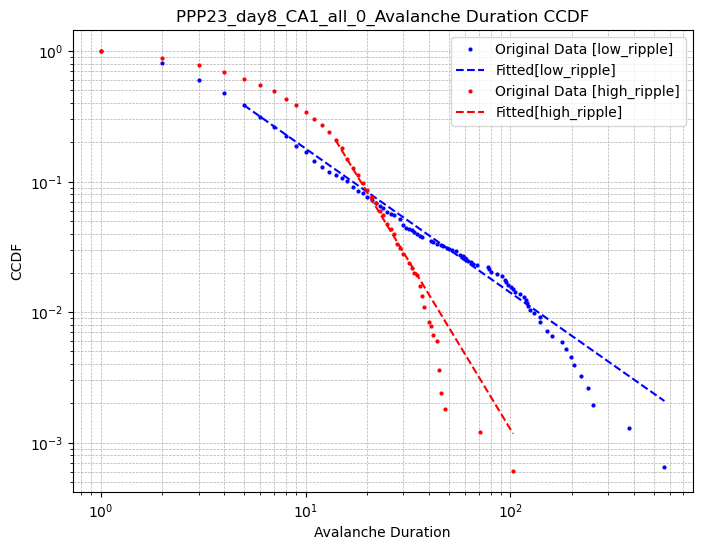

Results saved to D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\av_duration_all_sleep.csv
low_ripple: Beta=1.1714, R^2=0.9839
high_ripple: Beta=1.1237, R^2=0.9611


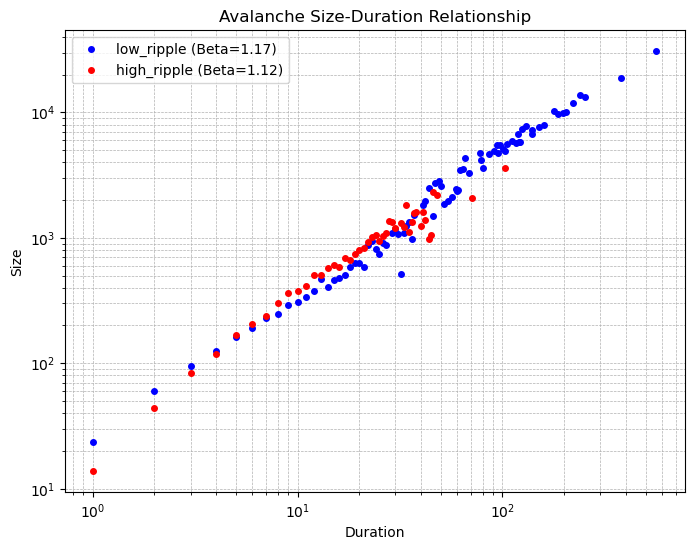

Results saved to D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\dcc_all_all_sleep.csv


{'low_ripple': {'beta_predicted': 1.0961613178291665,
  'obs_beta': 1.1714418695257105,
  'dcc': 0.07528055169654402},
 'high_ripple': {'beta_predicted': 1.0371424626667243,
  'obs_beta': 1.1237337131087992,
  'dcc': 0.08659125044207494}}

In [ ]:
run_dcc_pipeline(
    st_time=st.time,
    bin_size=0.05,
    pre_low_intervals=pre_low_intervals,
    pre_high_intervals=pre_high_intervals,
    xmins_size=[0,0],
    xmaxs_size=[0, 0],
    xmins_dur=[0, 0],
    xmaxs_dur=[0, 0],
    animal_name=animal_name,
    day=day,
    sleep_idx=0,
    animal=animal,
    brain_region=brain_region,
    cell_type=cell_type,
    base_dir=r"D:/Documents/GitHub/R_Project/PPP/codebook/Criticality_analysis/avalanche/data/l_h_ripples"
)

Calculating best minimal value for power law fit
low_ripple - KS Statistic: 0.0273, Alpha: 2.87, Xmin: 310.0,Xmax: 0
Lognormal vs Power-law: R=0.0054488429143289, p=0.849811994668141
Exponential vs Power-law: R=83.24251897296045, p=1.6415126712568936e-05
Calculating best minimal value for power law fit
high_ripple - KS Statistic: 0.0416, Alpha: 5.06, Xmin: 1177.0,Xmax: 0
Lognormal vs Power-law: R=0.048940384690226324, p=3.2048999591776653e-10
Exponential vs Power-law: R=4.781758255951259, p=0.14931855540603547


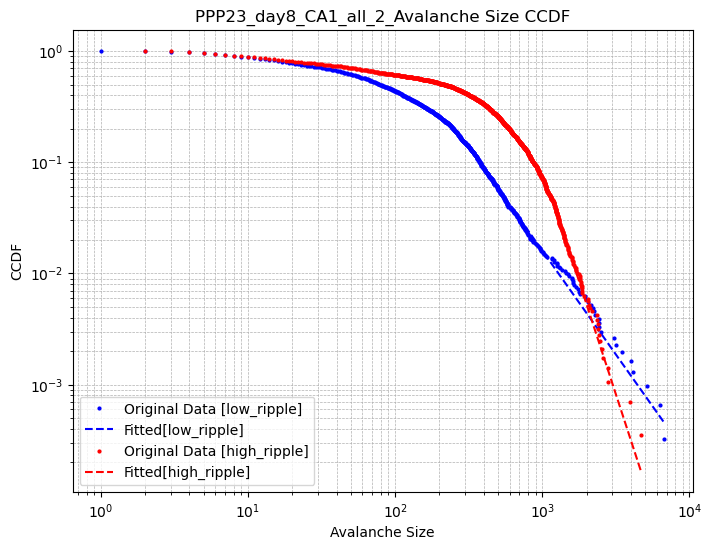

Results saved to D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\av_size_all_sleep.csv
Calculating best minimal value for power law fit
low_ripple - KS Statistic: 0.0244, Alpha: 3.18, Xmin: 15.0,Xmax: 0
Lognormal vs Power-law: R=-0.6124607640212489, p=0.4766071681762072
Exponential vs Power-law: R=37.52022983623977, p=0.0011517103390089206
Calculating best minimal value for power law fit
high_ripple - KS Statistic: 0.0313, Alpha: 4.85, Xmin: 25.0,Xmax: 0
Lognormal vs Power-law: R=0.0008336223607399162, p=0.9819378357312689
Exponential vs Power-law: R=7.015312733271421, p=0.15260764211420058


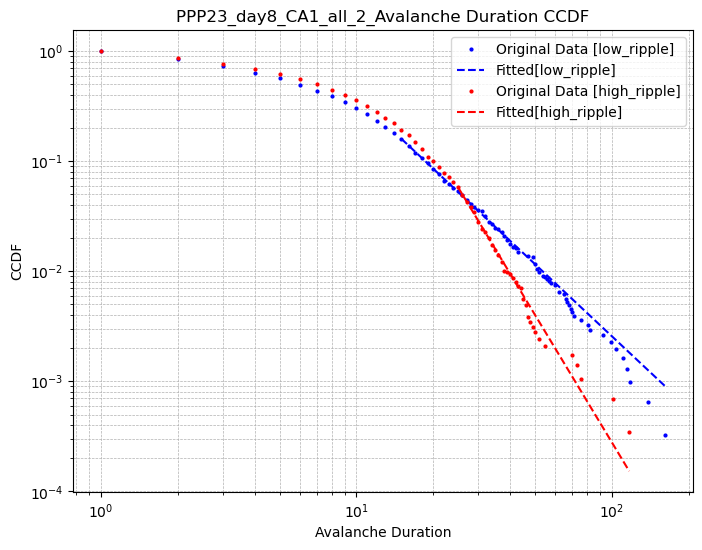

Results saved to D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\av_duration_all_sleep.csv
low_ripple: Beta=1.2101, R^2=0.9447
high_ripple: Beta=1.1472, R^2=0.9465


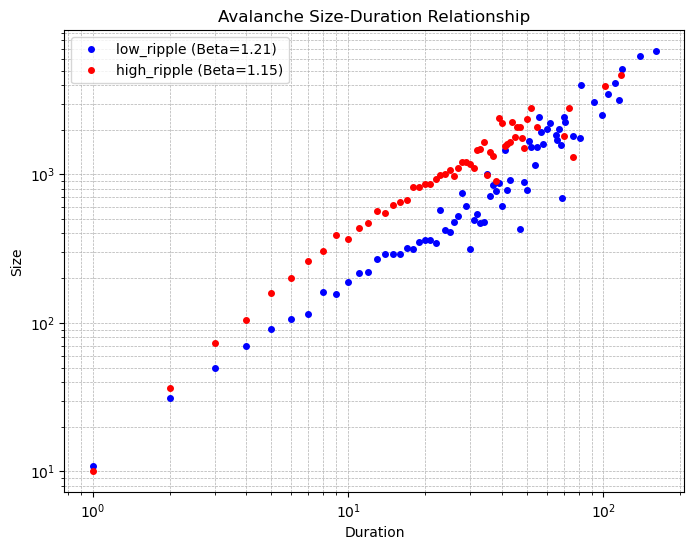

Results saved to D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\dcc_all_all_sleep.csv


{'low_ripple': {'beta_predicted': 1.164610524751511,
  'obs_beta': 1.2100526079537541,
  'dcc': 0.04544208320224308},
 'high_ripple': {'beta_predicted': 0.947095733670859,
  'obs_beta': 1.1472470932241003,
  'dcc': 0.20015135955324137}}

In [ ]:
run_dcc_pipeline(
    st_time=st.time,
    bin_size=0.05,
    pre_low_intervals=mid_low_intervals,
    pre_high_intervals=mid_high_intervals,
    xmins_size=[0, 0],
    xmaxs_size=[0, 0],
    xmins_dur=[0, 0],
    xmaxs_dur=[0, 0],
    animal_name=animal_name,
    day=day,
    sleep_idx=2,
    animal=animal,
    brain_region=brain_region,
    cell_type=cell_type,
    base_dir=r"D:/Documents/GitHub/R_Project/PPP/codebook/Criticality_analysis/avalanche/data/l_h_ripples"
)

Calculating best minimal value for power law fit
low_ripple - KS Statistic: 0.0385, Alpha: 3.06, Xmin: 310.0,Xmax: 0
Lognormal vs Power-law: R=-4.116210260783882, p=0.1501659889797368
Exponential vs Power-law: R=35.14509556276636, p=0.12181472189403103
Calculating best minimal value for power law fit
high_ripple - KS Statistic: 0.0461, Alpha: 2.79, Xmin: 794.0,Xmax: 0


c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\powerlaw.py:1570: RuntimeWarning: invalid value encountered in divide


Lognormal vs Power-law: R=0.031028238073167458, p=0.01434893235023588
Exponential vs Power-law: R=128.64163601924756, p=9.015336762145746e-10


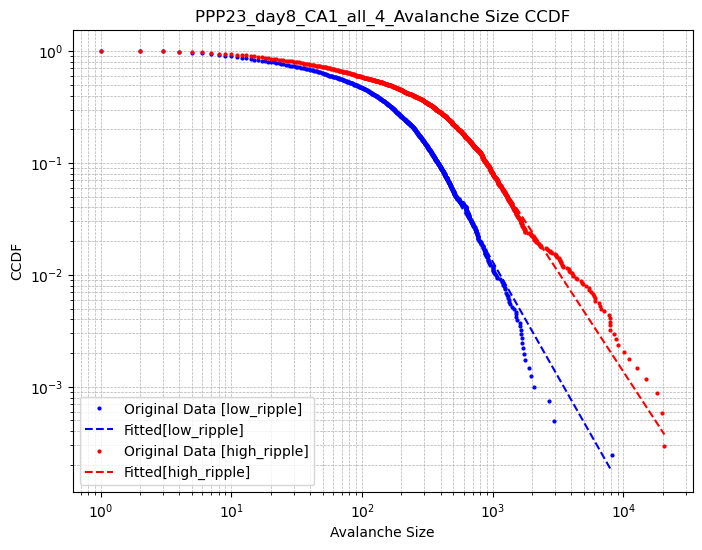

Results saved to D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\av_size_all_sleep.csv
Calculating best minimal value for power law fit
low_ripple - KS Statistic: 0.0247, Alpha: 3.63, Xmin: 16.0,Xmax: 0
Lognormal vs Power-law: R=-0.9920052285978134, p=0.42554969941003284
Exponential vs Power-law: R=25.96031867165999, p=0.03659718300906094
Calculating best minimal value for power law fit
high_ripple - KS Statistic: 0.0399, Alpha: 2.69, Xmin: 13.0,Xmax: 0
Lognormal vs Power-law: R=-0.0219862555824073, p=0.915373260558478
Exponential vs Power-law: R=157.58574196993203, p=1.563286860323532e-08


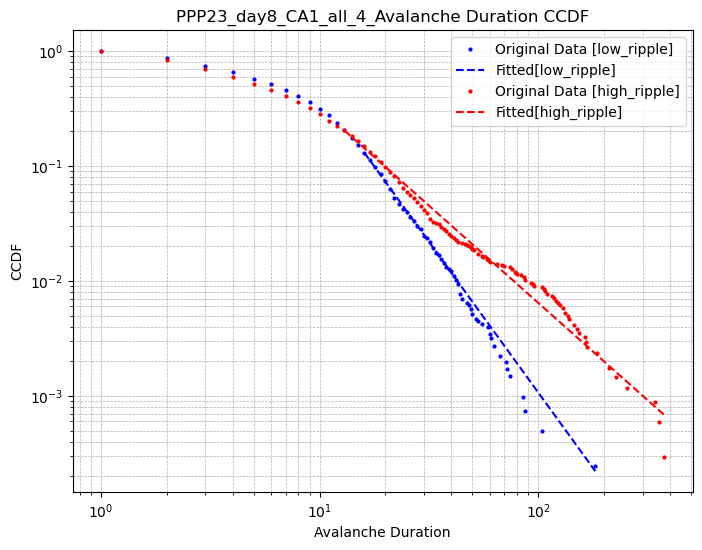

Results saved to D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\av_duration_all_sleep.csv
low_ripple: Beta=1.1535, R^2=0.9640
high_ripple: Beta=1.1056, R^2=0.9912


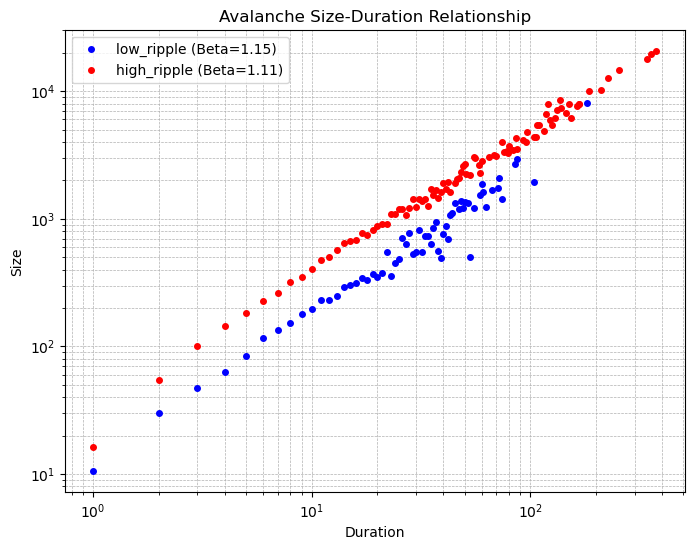

Results saved to D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\dcc_all_all_sleep.csv


{'low_ripple': {'beta_predicted': 1.2767716001054148,
  'obs_beta': 1.1535417882165673,
  'dcc': 0.12322981188884752},
 'high_ripple': {'beta_predicted': 0.9472231535334038,
  'obs_beta': 1.10556790124493,
  'dcc': 0.15834474771152618}}

In [ ]:
run_dcc_pipeline(
    st_time=st.time,
    bin_size=0.05,
    pre_low_intervals=post_low_intervals,
    pre_high_intervals=post_high_intervals,
    xmins_size=[0,0],
    xmaxs_size=[0, 0],
    xmins_dur=[0, 0],
    xmaxs_dur=[0, 0],
    animal_name=animal_name,
    day=day,
    sleep_idx=4,
    animal=animal,
    brain_region=brain_region,
    cell_type=cell_type,
    base_dir="D:/Documents/GitHub/R_Project/PPP/codebook/Criticality_analysis/avalanche/data/l_h_ripples"
)